In [1]:
!pip install -q tensorflow pandas numpy matplotlib scikit-learn requests

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [3]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 17.3850,
    "longitude": 78.4867,
    "start_date": "2015-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "pressure_msl_mean",
        "wind_speed_10m_max",
        "precipitation_sum"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)

response.raise_for_status()

weather = response.json()

df = pd.DataFrame(weather["daily"])

df.head()

,time,temperature_2m_mean,relative_humidity_2m_mean,pressure_msl_mean,wind_speed_10m_max,precipitation_sum
0,2015-01-01,23.3,69,1009.8,15.7,0.2
1,2015-01-02,23.1,72,1012.4,12.8,0.0
2,2015-01-03,22.4,84,1014.1,10.3,4.0
3,2015-01-04,21.7,85,1015.1,9.3,0.6
4,2015-01-05,22.1,70,1014.9,13.6,0.0


In [4]:
df.rename(columns={
    "time": "Date",
    "temperature_2m_mean": "Temperature",
    "relative_humidity_2m_mean": "Humidity",
    "pressure_msl_mean": "Pressure",
    "wind_speed_10m_max": "WindSpeed",
    "precipitation_sum": "Rainfall"
}, inplace=True)

df["Date"] = pd.to_datetime(df["Date"])

df = df.dropna()

print("Dataset downloaded successfully!")
print("Total records:", len(df))

display(df.head(10))

print(df.info())

Dataset downloaded successfully!
Total records: 4018


,Date,Temperature,Humidity,Pressure,WindSpeed,Rainfall
0,2015-01-01,23.3,69,1009.8,15.7,0.2
1,2015-01-02,23.1,72,1012.4,12.8,0.0
2,2015-01-03,22.4,84,1014.1,10.3,4.0
3,2015-01-04,21.7,85,1015.1,9.3,0.6
4,2015-01-05,22.1,70,1014.9,13.6,0.0
5,2015-01-06,21.5,61,1014.9,11.0,0.0
6,2015-01-07,22.2,52,1013.9,9.0,0.0
7,2015-01-08,21.6,52,1014.7,8.3,0.0
8,2015-01-09,20.0,42,1016.7,11.6,0.0
9,2015-01-10,19.1,42,1016.8,10.7,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         4018 non-null   datetime64[ns]
 1   Temperature  4018 non-null   float64       
 2   Humidity     4018 non-null   int64         
 3   Pressure     4018 non-null   float64       
 4   WindSpeed    4018 non-null   float64       
 5   Rainfall     4018 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 188.5 KB
None


In [5]:
df.to_csv("hyderabad_rainfall_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


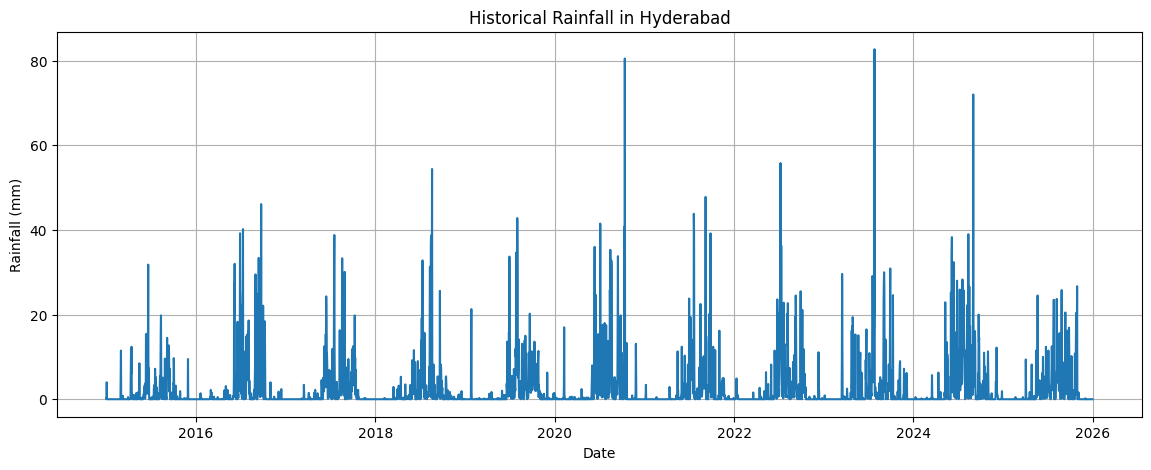

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["Rainfall"])

plt.title("Historical Rainfall in Hyderabad")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")

plt.grid()
plt.show()

In [7]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
display(df.head())

Dataset shape: (4018, 6)

Column names:
['Date', 'Temperature', 'Humidity', 'Pressure', 'WindSpeed', 'Rainfall']

Missing values:
Date           0
Temperature    0
Humidity       0
Pressure       0
WindSpeed      0
Rainfall       0
dtype: int64

Dataset information:


,Date,Temperature,Humidity,Pressure,WindSpeed,Rainfall
0,2015-01-01,23.3,69,1009.8,15.7,0.2
1,2015-01-02,23.1,72,1012.4,12.8,0.0
2,2015-01-03,22.4,84,1014.1,10.3,4.0
3,2015-01-04,21.7,85,1015.1,9.3,0.6
4,2015-01-05,22.1,70,1014.9,13.6,0.0


In [8]:
features = [
    "Temperature",
    "Humidity",
    "Pressure",
    "WindSpeed",
    "Rainfall"
]

data = df[features].values

print("Input data shape:", data.shape)

Input data shape: (4018, 5)


In [9]:
from sklearn.preprocessing import MinMaxScaler

# Split data chronologically before scaling
split_index = int(len(data) * 0.8)

# Separate input features and rainfall target
X_raw = data
y_raw = data[:, 4].reshape(-1, 1)

# Create separate scalers
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

# Fit scalers only on training data
feature_scaler.fit(X_raw[:split_index])
target_scaler.fit(y_raw[:split_index])

# Transform the complete dataset
X_scaled = feature_scaler.transform(X_raw)
y_scaled = target_scaler.transform(y_raw)

print("Normalization completed!")
print("Input shape:", X_scaled.shape)
print("Target shape:", y_scaled.shape)

Normalization completed!
Input shape: (4018, 5)
Target shape: (4018, 1)


In [10]:
X = []
y = []

sequence_length = 7

for i in range(sequence_length, len(X_scaled)):

    # Previous 7 days of weather
    X.append(X_scaled[i-sequence_length:i])

    # Rainfall of the next day
    y.append(y_scaled[i, 0])

X = np.array(X)
y = np.array(y)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (4011, 7, 5)
Output shape: (4011,)


In [11]:
# Identify the original target date for each sequence
target_indices = np.arange(sequence_length, len(X_scaled))

# Split chronologically
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

Training samples: 3207
Testing samples: 804
Training input shape: (3207, 7, 5)
Testing input shape: (804, 7, 5)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([

    LSTM(
        64,
        return_sequences=True,
        input_shape=(7, 5)
    ),

    Dropout(0.2),

    LSTM(32),

    Dense(16, activation='relu'),

    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0050 - mae: 0.0394 - val_loss: 0.0064 - val_mae: 0.0381
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0041 - mae: 0.0329 - val_loss: 0.0063 - val_mae: 0.0366
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0040 - mae: 0.0320 - val_loss: 0.0063 - val_mae: 0.0362
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0040 - mae: 0.0318 - val_loss: 0.0062 - val_mae: 0.0363
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0039 - mae: 0.0313 - val_loss: 0.0061 - val_mae: 0.0356
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0039 - mae: 0.0309 - val_loss: 0.0060 - val_mae: 0.0355
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0039 - mae: 0.0306 - val_loss: 0.0059 - val_mae: 0.0362
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0038 - mae: 0.0304 - val_loss: 0.0059 - val_mae: 0.0356
Epoch 9/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0037 - m

In [14]:
predictions = model.predict(X_test)

print("Predictions generated successfully!")

print("Prediction shape:", predictions.shape)
print("Actual values shape:", y_test.shape)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Predictions generated successfully!
Prediction shape: (804, 1)
Actual values shape: (804,)


In [15]:
# Convert normalized predictions back to mm

predicted_rainfall = target_scaler.inverse_transform(
    predictions
)

actual_rainfall = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# Rainfall cannot be negative
predicted_rainfall = np.maximum(predicted_rainfall, 0)

print("Predicted Rainfall (mm):")
print(predicted_rainfall[:10].flatten())

print("\nActual Rainfall (mm):")
print(actual_rainfall[:10].flatten())

Predicted Rainfall (mm):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Actual Rainfall (mm):
[0.  0.  0.  0.  0.  0.  0.  0.  0.1 1.8]


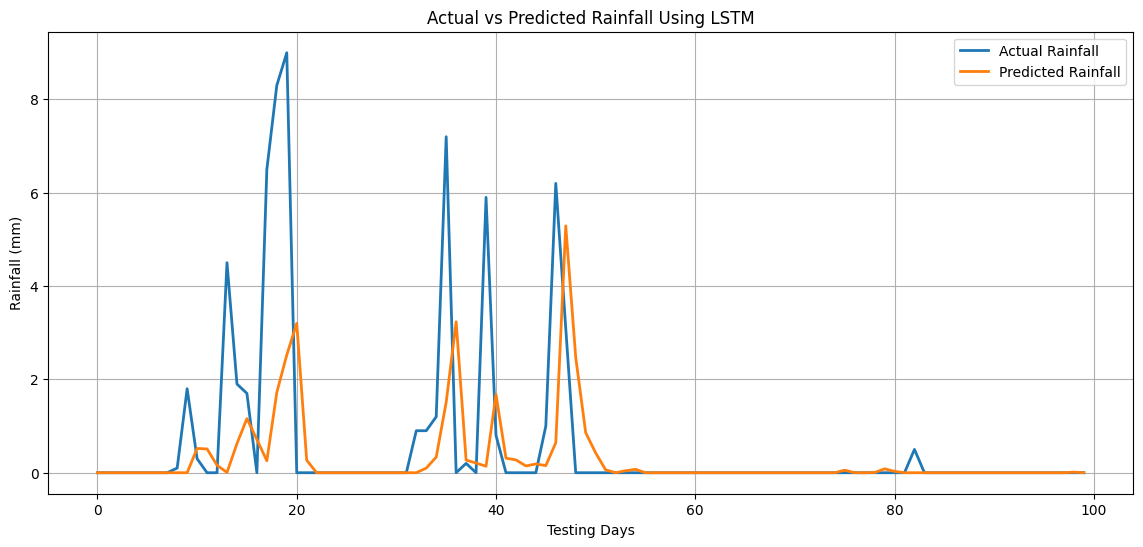

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_rainfall[:100],
    label="Actual Rainfall",
    linewidth=2
)

plt.plot(
    predicted_rainfall[:100],
    label="Predicted Rainfall",
    linewidth=2
)

plt.title("Actual vs Predicted Rainfall Using LSTM")

plt.xlabel("Testing Days")
plt.ylabel("Rainfall (mm)")

plt.legend()
plt.grid(True)

plt.show()

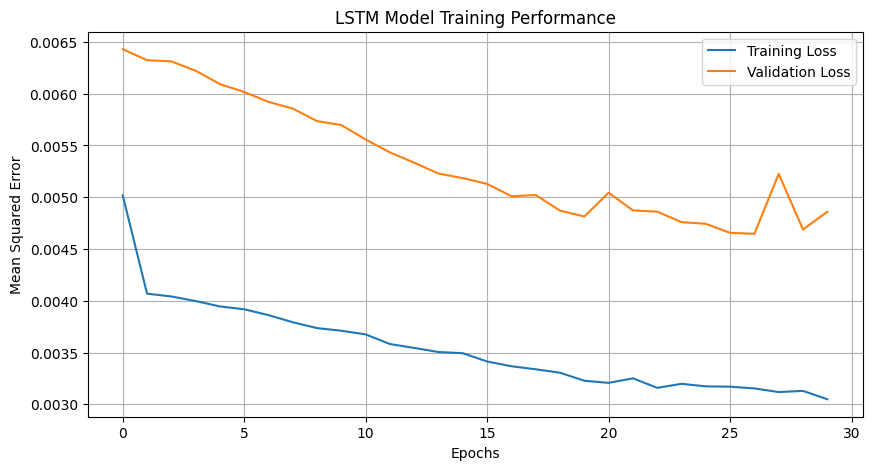

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Model Training Performance")

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)

plt.show()

In [18]:
# Get the latest 7 days of weather data

last_7_days = X_scaled[-7:]

# Reshape the data for LSTM

input_data = last_7_days.reshape(1, 7, 5)

# Generate prediction

next_day_prediction = model.predict(input_data)

# Convert to actual rainfall in mm

rainfall_mm = target_scaler.inverse_transform(
    next_day_prediction
)[0][0]

# Prevent negative rainfall predictions

rainfall_mm = max(0, rainfall_mm)

print("NEXT DAY RAINFALL PREDICTION")
print("----------------------------")

print("Location: Hyderabad")

print("Predicted Rainfall:",
      round(rainfall_mm, 2), "mm")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
NEXT DAY RAINFALL PREDICTION
----------------------------
Location: Hyderabad
Predicted Rainfall: 0 mm


In [19]:
# Save the trained LSTM model

model.save("rainfall_prediction_model.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [20]:
import joblib

joblib.dump(feature_scaler, "feature_scaler.pkl")

joblib.dump(target_scaler, "target_scaler.pkl")

print("Scalers saved successfully!")

Scalers saved successfully!


In [21]:
# STEP 5: CREATE SEQUENCES FOR LSTM

X = []
y = []

sequence_length = 7

for i in range(sequence_length, len(X_scaled)):

    X.append(X_scaled[i-7:i])

    y.append(y_scaled[i, 0])

X = np.array(X)
y = np.array(y)

print("Sequence creation completed!")

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Sequence creation completed!
Input shape: (4011, 7, 5)
Output shape: (4011,)


In [22]:
# STEP 6: SPLIT TRAINING AND TESTING DATA

# Find the original target dates
target_indices = np.arange(7, len(X_scaled))

# Create chronological split
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

# Training data
X_train = X[train_mask]
y_train = y[train_mask]

# Testing data
X_test = X[test_mask]
y_test = y[test_mask]

print("Data splitting completed!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

Data splitting completed!
Training samples: 3207
Testing samples: 804
Training input shape: (3207, 7, 5)
Testing input shape: (804, 7, 5)


In [23]:
# STEP 7: IMPORT LSTM MODEL COMPONENTS

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

print("LSTM components imported successfully!")

LSTM components imported successfully!


In [24]:
# CREATE LSTM DEEP LEARNING MODEL

model = Sequential([

    # First LSTM layer
    LSTM(
        64,
        return_sequences=True,
        input_shape=(7, 5)
    ),

    # Dropout layer
    Dropout(0.2),

    # Second LSTM layer
    LSTM(32),

    # Dense hidden layer
    Dense(16, activation='relu'),

    # Output layer
    Dense(1)

])

print("LSTM model created successfully!")

LSTM model created successfully!


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
# COMPILE THE LSTM MODEL

model.compile(

    optimizer='adam',

    loss='mean_squared_error',

    metrics=['mae']

)

print("Model compiled successfully!")

Model compiled successfully!


In [26]:
# DISPLAY MODEL SUMMARY

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 7, 64)          │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# STEP 8: TRAIN THE LSTM MODEL

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(

    X_train,

    y_train,

    epochs=30,

    batch_size=32,

    validation_split=0.2,

    callbacks=[early_stop],

    shuffle=False,

    verbose=1

)

print("LSTM model training completed!")

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0047 - mae: 0.0382 - val_loss: 0.0066 - val_mae: 0.0385
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0041 - mae: 0.0323 - val_loss: 0.0063 - val_mae: 0.0357
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0040 - mae: 0.0303 - val_loss: 0.0062 - val_mae: 0.0349
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0040 - mae: 0.0301 - val_loss: 0.0062 - val_mae: 0.0345
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0040 - mae: 0.0298 - val_loss: 0.0061 - val_mae: 0.0344
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0039 - mae: 0.0295 - val_loss: 0.0063 - val_mae: 0.0331
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0039 - mae: 0.0289 - val_loss: 0.0059 - val_mae: 0.0342
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0038 - mae: 0.0290 - val_loss: 0.0060 - val_mae: 0.0332
Epoch 9/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0038

In [28]:
# STEP 9: TEST THE TRAINED MODEL

predictions = model.predict(X_test)

print("Predictions generated successfully!")

print("Prediction shape:", predictions.shape)
print("Actual values shape:", y_test.shape)

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Predictions generated successfully!
Prediction shape: (804, 1)
Actual values shape: (804,)


In [29]:
# CONVERT NORMALIZED VALUES INTO MM

predicted_rainfall = target_scaler.inverse_transform(
    predictions
)

actual_rainfall = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# Rainfall cannot be negative
predicted_rainfall = np.maximum(predicted_rainfall, 0)

print("Predicted rainfall (first 10 days):")
print(np.round(predicted_rainfall[:10].flatten(), 2))

print("\nActual rainfall (first 10 days):")
print(np.round(actual_rainfall[:10].flatten(), 2))

Predicted rainfall (first 10 days):
[0.17 0.14 0.14 0.05 0.05 0.05 0.   0.   0.   0.  ]

Actual rainfall (first 10 days):
[0.  0.  0.  0.  0.  0.  0.  0.  0.1 1.8]


In [30]:
# MODEL EVALUATION

mae = mean_absolute_error(
    actual_rainfall,
    predicted_rainfall
)

rmse = np.sqrt(
    mean_squared_error(
        actual_rainfall,
        predicted_rainfall
    )
)

print("LSTM MODEL PERFORMANCE")
print("=======================")

print("Mean Absolute Error:", round(mae, 3), "mm")

print("Root Mean Squared Error:", round(rmse, 3), "mm")

LSTM MODEL PERFORMANCE
Mean Absolute Error: 2.198 mm
Root Mean Squared Error: 5.06 mm


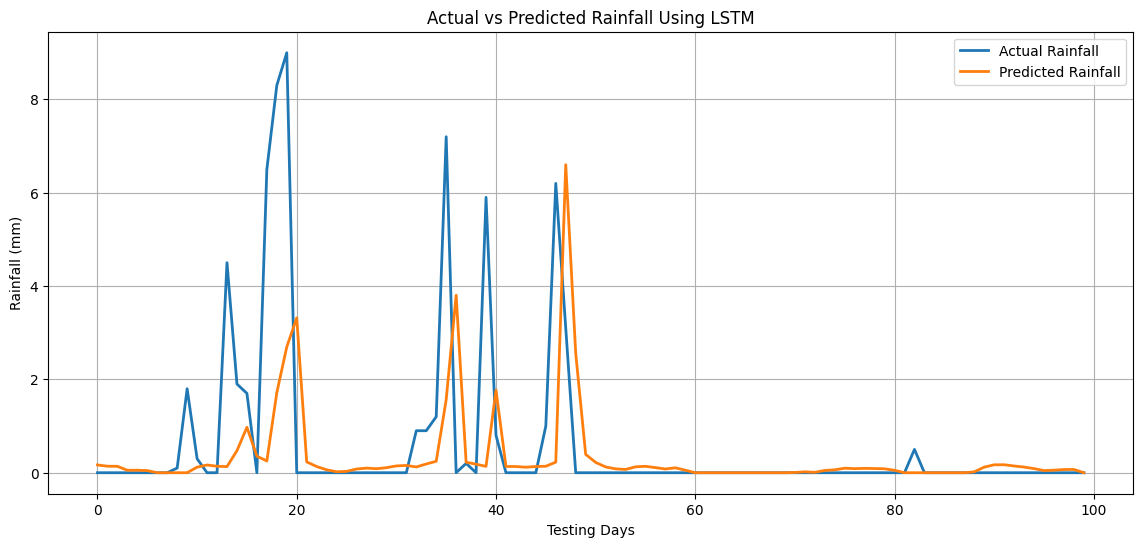

In [31]:
# ACTUAL VS PREDICTED RAINFALL GRAPH

plt.figure(figsize=(14, 6))

plt.plot(
    actual_rainfall[:100],
    label="Actual Rainfall",
    linewidth=2
)

plt.plot(
    predicted_rainfall[:100],
    label="Predicted Rainfall",
    linewidth=2
)

plt.title("Actual vs Predicted Rainfall Using LSTM")

plt.xlabel("Testing Days")

plt.ylabel("Rainfall (mm)")

plt.legend()

plt.grid(True)

plt.show()

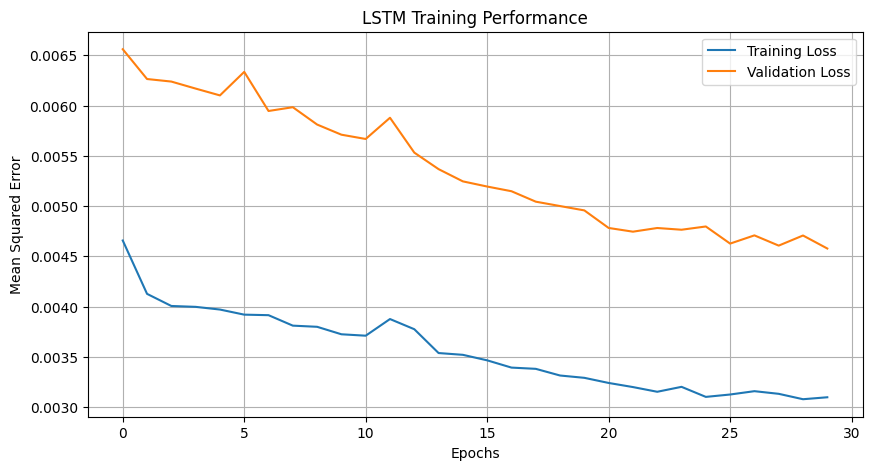

In [32]:
# TRAINING AND VALIDATION LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label="Training Loss"
)

plt.plot(
    history.history['val_loss'],
    label="Validation Loss"
)

plt.title("LSTM Training Performance")

plt.xlabel("Epochs")

plt.ylabel("Mean Squared Error")

plt.legend()

plt.grid(True)

plt.show()

In [33]:
# PREDICT NEXT DAY RAINFALL

last_7_days = X_scaled[-7:]

input_data = last_7_days.reshape(1, 7, 5)

next_prediction = model.predict(input_data)

rainfall_mm = target_scaler.inverse_transform(
    next_prediction
)[0][0]

rainfall_mm = max(0, rainfall_mm)

print("AI RAINFALL PREDICTION")
print("======================")

print("Location: Hyderabad")

print("Predicted Rainfall:",
      round(rainfall_mm, 2), "mm")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
AI RAINFALL PREDICTION
Location: Hyderabad
Predicted Rainfall: 0.05 mm


In [34]:
print("MODEL PERFORMANCE")

print("MAE:", round(mae, 3), "mm")

print("RMSE:", round(rmse, 3), "mm")

MODEL PERFORMANCE
MAE: 2.198 mm
RMSE: 5.06 mm


In [35]:
model.save("rainfall_prediction_model.keras")

import joblib

joblib.dump(feature_scaler, "feature_scaler.pkl")
joblib.dump(target_scaler, "target_scaler.pkl")

print("All model files saved successfully!")

All model files saved successfully!


In [36]:
!pip install -q gradio

In [37]:
import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [38]:
def predict_rainfall(weather_data):

    # Convert user inputs into an array
    weather_data = np.array(weather_data)

    # Normalize input using our saved scaler
    scaled_input = feature_scaler.transform(weather_data)

    # Reshape for LSTM
    scaled_input = scaled_input.reshape(1, 7, 5)

    # Predict rainfall
    prediction = model.predict(scaled_input, verbose=0)

    # Convert prediction into mm
    rainfall = target_scaler.inverse_transform(
        prediction
    )[0][0]

    rainfall = max(0, rainfall)

    return round(float(rainfall), 2)

In [39]:
def rainfall_dashboard():

    # Get latest seven days
    latest_data = df[
        ["Temperature", "Humidity",
         "Pressure", "WindSpeed", "Rainfall"]
    ].tail(7).values

    # Predict rainfall
    result = predict_rainfall(latest_data)

    # Display prediction
    return (
        f"Location: Hyderabad\n"
        f"Predicted Rainfall: {result} mm\n"
    )

In [42]:
with gr.Blocks() as demo:

    gr.Markdown(
        """
        # 🌧️ AI-Based Rainfall Prediction System

        ### Deep Learning using LSTM Neural Network

        Predict next-day rainfall for Hyderabad using
        historical weather observations.
        """
    )

    predict_button = gr.Button(
        "Predict Rainfall",
        variant="primary"
    )

    output = gr.Textbox(
        label="AI Rainfall Prediction",
        lines=3
    )

    predict_button.click(
        fn=rainfall_dashboard,
        outputs=output
    )
demo.launch(
    share=True,
    debug=True,
    theme=gr.themes.Soft()
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2f3bf03d165df4c6a8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://2f3bf03d165df4c6a8.gradio.live


In [43]:
!pip install -q --upgrade gradio

In [46]:

import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. PREPARE THE WEATHER INPUT TABLE
# ------------------------------------------

features = [
    "Temperature",
    "Humidity",
    "Pressure",
    "WindSpeed",
    "Rainfall"
]

latest_weather = (
    df[features]
    .tail(7)
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------
# 2. PREDICTION FUNCTION
# ------------------------------------------

def predict_dashboard(weather_input):

    # Handle Gradio DataFrame input
    if isinstance(weather_input, pd.DataFrame):
        weather_input = weather_input[features].values

    weather_input = np.asarray(
        weather_input, dtype=float
    )

    if weather_input.shape != (7, 5):
        raise gr.Error("Please provide 7 days of weather data.")

    if not np.isfinite(weather_input).all():
        raise gr.Error("Please enter valid numerical values.")

    # Scale input
    scaled_input = feature_scaler.transform(weather_input)

    # Reshape for LSTM
    scaled_input = scaled_input.reshape(1, 7, 5)

    # Predict
    prediction = model.predict(scaled_input, verbose=0)

    rainfall = target_scaler.inverse_transform(
        prediction
    )[0][0]

    rainfall = max(0, float(rainfall))

    # Get historical dates
    dates = pd.to_datetime(df["Date"].tail(7))

    labels = [
        date.strftime("%d %b") for date in dates
    ]

    next_date = dates.iloc[-1] + pd.Timedelta(days=1)
    labels.append(next_date.strftime("%d %b"))

    # Historical rainfall + predicted rainfall
    rainfall_values = list(weather_input[:, 4])
    rainfall_values.append(rainfall)

    # Create improved chart
    fig, ax = plt.subplots(figsize=(12, 5))

    bars = ax.bar(
        labels,
        rainfall_values,
        width=0.6
    )

    bars[-1].set_color("#4F46E5")

    ax.set_title(
        "7-Day Historical Rainfall vs Next-Day Prediction",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Rainfall (mm)")

    ax.grid(axis="y", alpha=0.25)

    ax.legend(
        [bars[0], bars[-1]],
        ["Historical Rainfall", "AI Prediction"]
    )

    plt.tight_layout()

    result = f"""
# 🌧️ Rainfall Prediction Result

**Location:** Hyderabad, Telangana

## {rainfall:.2f} mm

**Forecast date:** {next_date.strftime("%d %B %Y")}

**Model:** LSTM Deep Learning

**Input:** Seven days of weather observations

*Experimental prediction based on the trained model.*
"""

    return result, round(rainfall, 2), fig

    # --------------------------------------
    # 3. CREATE PREDICTION CHART
    # --------------------------------------

    fig, ax = plt.subplots(figsize=(10, 4))

    days = [
        "Day 1", "Day 2", "Day 3",
        "Day 4", "Day 5", "Day 6",
        "Day 7", "Predicted"
    ]

    rainfall_values = list(weather_input[:, 4])
    rainfall_values.append(rainfall)

    bars = ax.bar(
        days,
        rainfall_values
    )

    bars[-1].set_color("#4F46E5")

    ax.set_title(
        "Historical and Predicted Rainfall",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Rainfall (mm)")
    ax.set_xlabel("Weather observation sequence")

    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()

    # --------------------------------------
    # 4. RESULT MESSAGE
    # --------------------------------------

    result = f"""
## Rainfall prediction generated successfully

**Location:** Hyderabad, Telangana

**Predicted rainfall:** {rainfall:.2f} mm

**Model:** LSTM Deep Learning

**Input:** Previous 7 days of weather observations

*This is an experimental model estimate, not a live weather forecast.*
"""

    return result, round(rainfall, 2), fig


# ------------------------------------------
# 5. DASHBOARD DESIGN
# ------------------------------------------

custom_css = """
.gradio-container {
    max-width: 1250px !important;
    margin: auto !important;
    background: #f3f6fb !important;
}

#main-header {
    background: linear-gradient(120deg, #101c3b, #263f79);
    padding: 30px;
    border-radius: 18px;
    color: white;
    margin-bottom: 20px;
}

#main-header h1 {
    color: white;
    font-size: 30px;
}

#main-header p {
    color: #dce7ff;
}

.panel {
    background: white;
    padding: 20px;
    border-radius: 15px;
    border: 1px solid #e5eaf2;
}

#predict-button {
    background: #4f46e5 !important;
    color: white !important;
    border-radius: 10px !important;
    font-weight: bold !important;
    min-height: 48px;
}

#result-card {
    background: white;
    border: 1px solid #e5eaf2;
    border-radius: 15px;
    padding: 20px;
}
"""

# ------------------------------------------
# 6. CREATE GRADIO APPLICATION
# ------------------------------------------

with gr.Blocks(
    css=custom_css,
    title="AI Rainfall Prediction System"
) as demo:

    gr.HTML("""
    <div id="main-header">
        <h1>🌧️ AI Rainfall Prediction System</h1>
        <h3>Intelligent Weather Forecasting using Deep Learning</h3>
        <p>
        Hyderabad, Telangana |
        LSTM Neural Network |
        Historical Weather Analytics
        </p>
    </div>
    """)

    gr.Markdown("## Weather Analytics Dashboard")

    with gr.Row():

        with gr.Column():
            gr.Markdown(
                """
                <div class="panel">

                ### 📍 Project Location

                **Hyderabad, Telangana**

                ### 🧠 AI Model

                LSTM Neural Network

                ### 📊 Input Features

                Temperature, humidity, pressure,
                wind speed and previous rainfall.

                ### ⏳ Sequence Length

                7 consecutive daily observations.

                </div>
                """
            )

        with gr.Column():
            gr.Markdown(
                """
                <div class="panel">

                ### 📁 Dataset Information

                Historical weather observations

                ### 📅 Dataset Period

                January 2015 – December 2025

                ### 🔬 Learning Method

                Supervised Deep Learning

                ### 🎯 Prediction Target

                Next-day rainfall in millimetres.

                </div>
                """
            )

    gr.Markdown("## Enter Weather Observations")

    gr.Markdown(
        """
        Edit the values below to experiment with different
        seven-day weather sequences.

        Keep all values in their original units.
        """
    )

    weather_table = gr.Dataframe(
        value=latest_weather,
        headers=features,
        datatype="number",
        row_count=7,
        col_count=(5, "fixed"),
        interactive=True,
        label="Seven-Day Weather Input"
    )

    predict_button = gr.Button(
        "🌧️ Generate Rainfall Prediction",
        elem_id="predict-button"
    )

    gr.Markdown("## AI Prediction Results")

    with gr.Row():

        with gr.Column():
            result_text = gr.Markdown(
                """
                Your prediction will appear here
                after clicking the prediction button.
                """,
                elem_id="result-card"
            )

        with gr.Column():
            result_number = gr.Number(
                label="Predicted Rainfall (mm)",
                precision=2,
                interactive=False
            )

    prediction_chart = gr.Plot(
        label="Rainfall Analysis"
    )

    gr.Markdown("## Model Performance")

    if "mae" in globals() and "rmse" in globals():

        gr.Markdown(
            f"""
            | Evaluation Metric | Result |
            |---|---:|
            | Mean Absolute Error | {mae:.3f} mm |
            | Root Mean Squared Error | {rmse:.3f} mm |
            """
        )

    else:
        gr.Markdown(
            "Run model evaluation to display MAE and RMSE."
        )

    predict_button.click(
        fn=predict_dashboard,
        inputs=weather_table,
        outputs=[
            result_text,
            result_number,
            prediction_chart
        ]
    )

    gr.Markdown(
        """
        ---
        **AI Rainfall Prediction System**

        Developed using Python, TensorFlow, LSTM,
        Pandas, Matplotlib and Gradio.

        *Academic demonstration project.*
        """
    )

# ------------------------------------------
# 7. LAUNCH APPLICATION
# ------------------------------------------

demo.launch(
    share=True,
    debug=False,
    theme=gr.themes.Soft()
)


/tmp/ipykernel_333/1131712061.py:232: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(
/usr/local/lib/python3.13/dist-packages/gradio/components/dataframe.py:192: UserWarning: The `col_count` parameter is deprecated and will be removed. Please use `column_count` instead.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://66211ab9021847c34f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [45]:
# DIAGNOSTIC: CHECK LSTM PREDICTION VARIATION

def test_model_response(weather_data):

    scaled = feature_scaler.transform(weather_data)

    sequence = scaled.reshape(1, 7, 5)

    pred = model.predict(sequence, verbose=0)

    return float(
        target_scaler.inverse_transform(pred)[0][0]
    )

# Original seven-day weather data
original_input = df[features].tail(7).values.copy()

# Create a second test input with different weather conditions
modified_input = original_input.copy()

modified_input[:, 0] += 3       # Increase temperature
modified_input[:, 1] = np.clip(
    modified_input[:, 1] + 10, 0, 100
)                                # Increase humidity
modified_input[:, 4] += 5       # Increase previous rainfall

# Get predictions
prediction_1 = test_model_response(original_input)
prediction_2 = test_model_response(modified_input)

print("MODEL RESPONSE TEST")
print("-------------------")

print("Original prediction:",
      round(max(0, prediction_1), 3), "mm")

print("Modified prediction:",
      round(max(0, prediction_2), 3), "mm")

print("Difference:",
      round(abs(prediction_1 - prediction_2), 3), "mm")

print("\nRainfall dataset statistics:")
print(df["Rainfall"].describe())

MODEL RESPONSE TEST
-------------------
Original prediction: 0.046 mm
Modified prediction: 0.248 mm
Difference: 0.202 mm

Rainfall dataset statistics:
count    4018.000000
mean        2.420159
std         6.045853
min         0.000000
25%         0.000000
50%         0.000000
75%         1.700000
max        82.700000
Name: Rainfall, dtype: float64


In [47]:
# STEP 1: COMPARE LSTM WITH BASELINE MODELS

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

# Actual rainfall values in mm
actual = actual_rainfall.flatten()

# LSTM predictions
lstm_predictions = predicted_rainfall.flatten()

# Baseline 1: Always predict zero rainfall
zero_predictions = np.zeros(len(actual))

# Baseline 2: Always predict training mean rainfall
train_mean_mm = target_scaler.inverse_transform(
    y_train.reshape(-1, 1)
).mean()

mean_predictions = np.full(
    len(actual),
    train_mean_mm
)

# Evaluation function
def evaluate(name, predictions):

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    print(name)
    print("MAE:", round(mae, 3), "mm")
    print("RMSE:", round(rmse, 3), "mm")
    print("----------------------")


evaluate("LSTM MODEL", lstm_predictions)

evaluate("ZERO RAINFALL BASELINE", zero_predictions)

evaluate("MEAN RAINFALL BASELINE", mean_predictions)

LSTM MODEL
MAE: 2.198 mm
RMSE: 5.06 mm
----------------------
ZERO RAINFALL BASELINE
MAE: 2.737 mm
RMSE: 6.616 mm
----------------------
MEAN RAINFALL BASELINE
MAE: 3.518 mm
RMSE: 6.035 mm
----------------------


In [48]:
# STEP: RAINFALL CLASSIFICATION EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Define measurable rainfall threshold
threshold = 0.1

# Convert actual rainfall into classes
actual_classes = (
    actual_rainfall.flatten() >= threshold
).astype(int)

# Convert predicted rainfall into classes
predicted_classes = (
    predicted_rainfall.flatten() >= threshold
).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

precision = precision_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

recall = recall_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

f1 = f1_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

print("RAINFALL CLASSIFICATION RESULTS")
print("--------------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1, 3))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    actual_classes,
    predicted_classes
))

print("\nCLASSIFICATION REPORT")

print(classification_report(
    actual_classes,
    predicted_classes,
    target_names=["No Rain", "Rain"],
    zero_division=0
))

RAINFALL CLASSIFICATION RESULTS
--------------------------------
Accuracy: 77.36 %
Precision: 68.59 %
Recall: 96.6 %
F1 Score: 0.802

CONFUSION MATRIX
[[253 169]
 [ 13 369]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     No Rain       0.95      0.60      0.74       422
        Rain       0.69      0.97      0.80       382

    accuracy                           0.77       804
   macro avg       0.82      0.78      0.77       804
weighted avg       0.83      0.77      0.77       804



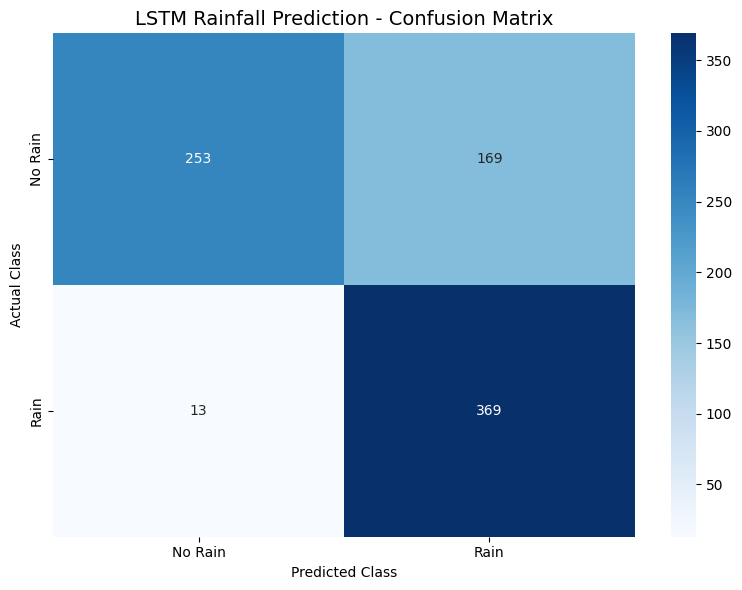

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Rain', 'Rain'],
    yticklabels=['No Rain', 'Rain']
)

plt.title(
    'LSTM Rainfall Prediction - Confusion Matrix',
    fontsize=14
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [50]:
!pip install -q --upgrade gradio plotly

In [51]:
import numpy as np
import pandas as pd
import gradio as gr
import plotly.graph_objects as go

from sklearn.metrics import confusion_matrix

# Weather features
features = [
    "Temperature",
    "Humidity",
    "Pressure",
    "WindSpeed",
    "Rainfall"
]

# Latest seven observations
latest_weather = (
    df[features]
    .tail(7)
    .reset_index(drop=True)
    .copy()
)

# Store evaluation metrics
dashboard_mae = mean_absolute_error(
    actual_rainfall,
    predicted_rainfall
)

dashboard_rmse = np.sqrt(
    mean_squared_error(
        actual_rainfall,
        predicted_rainfall
    )
)

dashboard_accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

dashboard_precision = precision_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

dashboard_recall = recall_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

dashboard_f1 = f1_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

print("Dashboard data prepared successfully!")

Dashboard data prepared successfully!


In [55]:

# ==========================================
# PROFESSIONAL AI RAINFALL DASHBOARD
# ==========================================

# ==========================================
# RAINVISION AI - COMPLETE PROFESSIONAL DASHBOARD
# ==========================================

import gradio as gr
import plotly.graph_objects as go
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# 1. PREPARE DASHBOARD DATA
# ==========================================

features = [
    "Temperature",
    "Humidity",
    "Pressure",
    "WindSpeed",
    "Rainfall"
]

latest_weather = (
    df[features]
    .tail(7)
    .reset_index(drop=True)
    .copy()
)

dashboard_mae = mean_absolute_error(
    actual_rainfall.flatten(),
    predicted_rainfall.flatten()
)

dashboard_rmse = np.sqrt(
    mean_squared_error(
        actual_rainfall.flatten(),
        predicted_rainfall.flatten()
    )
)

dashboard_accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

dashboard_precision = precision_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

dashboard_recall = recall_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

dashboard_f1 = f1_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)


# ==========================================
# 2. HISTORICAL RAINFALL CHART
# ==========================================

def create_history_chart():

    recent = df.tail(30)

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=recent["Date"],
        y=recent["Rainfall"],
        name="Historical Rainfall",
        marker_color="#4285F4",
        hovertemplate="%{x}<br>Rainfall: %{y:.2f} mm<extra></extra>"
    ))

    fig.update_layout(
        title="Rainfall History - Last 30 Days",
        xaxis_title="Date",
        yaxis_title="Rainfall (mm)",
        template="plotly_white",
        height=380
    )

    return fig


# ==========================================
# 3. ACTUAL VS PREDICTED CHART
# ==========================================

def create_comparison_chart():

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        y=actual_rainfall.flatten()[:100],
        mode="lines",
        name="Actual Rainfall",
        line=dict(color="#2563EB", width=2)
    ))

    fig.add_trace(go.Scatter(
        y=predicted_rainfall.flatten()[:100],
        mode="lines",
        name="Predicted Rainfall",
        line=dict(color="#F59E0B", width=2)
    ))

    fig.update_layout(
        title="Actual vs Predicted Rainfall",
        xaxis_title="Testing Observations",
        yaxis_title="Rainfall (mm)",
        template="plotly_white",
        height=380
    )

    return fig


# ==========================================
# 4. CONFUSION MATRIX
# ==========================================

def create_confusion_chart():

    cm = confusion_matrix(
        actual_classes,
        predicted_classes
    )

    fig = go.Figure(data=go.Heatmap(
        z=cm,
        x=["No Rain", "Rain"],
        y=["No Rain", "Rain"],
        text=cm,
        texttemplate="%{text}",
        colorscale="Blues",
        showscale=True
    ))

    fig.update_layout(
        title="Rainfall Classification Confusion Matrix",
        xaxis_title="Predicted Class",
        yaxis_title="Actual Class",
        template="plotly_white",
        height=380
    )

    return fig


# ==========================================
# 5. PREDICTION FUNCTION
# ==========================================


def generate_prediction(weather_input):

    if isinstance(weather_input, pd.DataFrame):
        weather_input = weather_input[features].values

    weather_input = np.asarray(weather_input, dtype=float)

    if weather_input.shape != (7, 5):
        raise gr.Error("Please enter exactly 7 rows and 5 columns.")

    if not np.isfinite(weather_input).all():
        raise gr.Error("Please enter valid numerical values.")

    if np.any(weather_input[:, 1] < 0) or np.any(weather_input[:, 1] > 100):
        raise gr.Error("Humidity must be between 0 and 100.")

    if np.any(weather_input[:, 4] < 0):
        raise gr.Error("Rainfall cannot be negative.")

    # Scale the seven input days
    scaled_input = feature_scaler.transform(weather_input)

    # Keep a rolling seven-day input sequence
    current_sequence = scaled_input.copy()

    future_predictions = []

    # Generate seven consecutive predictions
    for day in range(7):

        model_input = current_sequence.reshape(1, 7, 5)

        prediction_scaled = model.predict(
            model_input,
            verbose=0
        )

        predicted_mm = target_scaler.inverse_transform(
            prediction_scaled
        )[0][0]

        predicted_mm = max(0, float(predicted_mm))

        future_predictions.append(predicted_mm)

        # Create the next input row using the predicted rainfall.
        # Other weather variables are held at the last observed values.
        next_row = current_sequence[-1].copy()

        next_row[4] = target_scaler.transform(
            np.array([[predicted_mm]])
        )[0][0]

        # Shift the sequence forward
        current_sequence = np.vstack([
            current_sequence[1:],
            next_row
        ])

    # Build seven-day prediction chart
    labels = [
        "Day 1", "Day 2", "Day 3",
        "Day 4", "Day 5", "Day 6", "Day 7"
    ]

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=labels,
        y=future_predictions,
        marker_color="#2563EB",
        text=[f"{value:.2f} mm" for value in future_predictions],
        textposition="outside",
        cliponaxis=False,
        name="Predicted Rainfall"
    ))

    max_value = max(future_predictions)
    axis_max = max(1, max_value * 1.35)

    fig.update_layout(
        title="AI-Based 7-Day Rainfall Prediction",
        xaxis_title="Forecast Days",
        yaxis_title="Predicted Rainfall (mm)",
        template="plotly_white",
        height=430,
        showlegend=False,
        yaxis=dict(range=[0, axis_max])
    )

    # Display all seven predictions
    prediction_table = pd.DataFrame({
        "Forecast Day": labels,
        "Predicted Rainfall (mm)": [
            round(value, 2) for value in future_predictions
        ]
    })

    result = f"""
## 🌧️ Seven-Day Rainfall Forecast

**Location:** Hyderabad, Telangana

**Model:** LSTM Deep Learning

**Forecast Period:** Next 7 days

{prediction_table.to_markdown(index=False)}

*Experimental multi-step model estimates, not verified live weather forecasts.*
"""

    return result, round(future_predictions[0], 2), fig



# ==========================================
# 6. PROFESSIONAL BLUE-WHITE DESIGN
# ==========================================

css = """
.gradio-container {
    max-width: 1450px !important;
    background: #f4f7fc !important;
}

#header {
    background: linear-gradient(120deg, #102b55, #2463a5);
    color: white;
    padding: 28px;
    border-radius: 16px;
    margin-bottom: 18px;
}

#header h1,
#header p {
    color: white !important;
}

.metric-card {
    background: white;
    padding: 18px;
    border-radius: 13px;
    border: 1px solid #e3eaf4;
    min-height: 105px;
}

.metric-label {
    color: #64748b;
    font-size: 13px;
}

.metric-value {
    color: #173d70;
    font-size: 27px;
    font-weight: 700;
}

#predict-btn {
    background: #1769aa !important;
    color: white !important;
    font-weight: bold !important;
    min-height: 48px;
}

footer {
    display: none !important;
}
"""


# ==========================================
# 7. BUILD DASHBOARD
# ==========================================

with gr.Blocks(
    title="AI Rainfall Analytics",
    css=css
) as demo:

    # HEADER
    gr.HTML("""
    <div id="header">
        <h1>🌧️ RainVision AI</h1>
        <p>Intelligent Rainfall Prediction & Weather Analytics</p>
        <p>HYDERABAD, TELANGANA | LSTM DEEP LEARNING SYSTEM</p>
    </div>
    """)

    # NAVIGATION
    with gr.Row():

        overview_btn = gr.Button("Overview")
        prediction_btn = gr.Button("AI Prediction")
        analytics_btn = gr.Button("Analytics")
        performance_btn = gr.Button("Model Performance")

    # ======================================
    # OVERVIEW
    # ======================================

    with gr.Column(visible=True) as overview_section:

        gr.Markdown("## Weather Analytics Overview")

        with gr.Row():

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Average Rainfall</div>
                <div class="metric-value">
                    {df['Rainfall'].mean():.2f} mm
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Average Temperature</div>
                <div class="metric-value">
                    {df['Temperature'].mean():.1f} °C
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Average Humidity</div>
                <div class="metric-value">
                    {df['Humidity'].mean():.1f} %
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Average Wind Speed</div>
                <div class="metric-value">
                    {df['WindSpeed'].mean():.1f}
                </div>
            </div>
            """)

        gr.Markdown("### Historical Rainfall Analytics")

        gr.Plot(value=create_history_chart())


    # ======================================
    # AI PREDICTION
    # ======================================

    with gr.Column(visible=False) as prediction_section:

        gr.Markdown("## AI Rainfall Prediction")

        gr.Markdown(
            "Enter or modify seven consecutive days of weather data."
        )

        weather_table = gr.Dataframe(
            value=latest_weather,
            headers=features,
            datatype="number",
            row_count=7,
            col_count=(5, "fixed"),
            interactive=True,
            label="Weather Observation Input"
        )

        predict_btn = gr.Button(
            "🌧️ Generate AI Prediction",
            elem_id="predict-btn"
        )

        with gr.Row():

            prediction_result = gr.Markdown(
                "Your prediction will appear here."
            )

            prediction_value = gr.Number(
                label="Predicted Rainfall (mm)",
                precision=2,
                interactive=False
            )

        prediction_chart = gr.Plot()

        predict_btn.click(
            fn=generate_prediction,
            inputs=weather_table,
            outputs=[
                prediction_result,
                prediction_value,
                prediction_chart
            ]
        )


    # ======================================
    # ANALYTICS
    # ======================================

    with gr.Column(visible=False) as analytics_section:

        gr.Markdown("## Rainfall Analytics")

        gr.Plot(value=create_history_chart())

        gr.Plot(value=create_comparison_chart())


    # ======================================
    # MODEL PERFORMANCE
    # ======================================

    with gr.Column(visible=False) as performance_section:

        gr.Markdown("## LSTM Model Performance")

        with gr.Row():

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">MAE</div>
                <div class="metric-value">
                    {dashboard_mae:.3f} mm
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">RMSE</div>
                <div class="metric-value">
                    {dashboard_rmse:.3f} mm
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Classification Accuracy</div>
                <div class="metric-value">
                    {dashboard_accuracy * 100:.2f}%
                </div>
            </div>
            """)

            gr.HTML(f"""
            <div class="metric-card">
                <div class="metric-label">Rainfall F1 Score</div>
                <div class="metric-value">
                    {dashboard_f1:.3f}
                </div>
            </div>
            """)

        gr.Markdown("### Classification Metrics")

        gr.Markdown(f"""
| Metric | Result |
|---|---:|
| Precision | {dashboard_precision * 100:.2f}% |
| Recall | {dashboard_recall * 100:.2f}% |
| F1 Score | {dashboard_f1:.3f} |
""")

        gr.Markdown(
            "*Classification metrics are calculated by applying a rainfall threshold to the regression predictions.*"
        )

        gr.Plot(value=create_confusion_chart())


    # ======================================
    # NAVIGATION
    # ======================================

    def navigate(page):

        return (
            gr.update(visible=page == "overview"),
            gr.update(visible=page == "prediction"),
            gr.update(visible=page == "analytics"),
            gr.update(visible=page == "performance")
        )

    overview_btn.click(
        lambda: navigate("overview"),
        outputs=[
            overview_section,
            prediction_section,
            analytics_section,
            performance_section
        ]
    )

    prediction_btn.click(
        lambda: navigate("prediction"),
        outputs=[
            overview_section,
            prediction_section,
            analytics_section,
            performance_section
        ]
    )

    analytics_btn.click(
        lambda: navigate("analytics"),
        outputs=[
            overview_section,
            prediction_section,
            analytics_section,
            performance_section
        ]
    )

    performance_btn.click(
        lambda: navigate("performance"),
        outputs=[
            overview_section,
            prediction_section,
            analytics_section,
            performance_section
        ]
    )

    # FOOTER
    gr.Markdown("""
---
**RainVision AI | Academic Deep Learning Project**

Developed using Python, TensorFlow, LSTM, Pandas, Plotly and Gradio.

Historical-data-based experimental predictions.
""")


# ==========================================
# 8. LAUNCH DASHBOARD
# ==========================================

demo.launch(
    share=True,
    debug=False,
    theme=gr.themes.Soft()
)


/tmp/ipykernel_333/2755453474.py:353: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(
/usr/local/lib/python3.13/dist-packages/gradio/components/dataframe.py:192: UserWarning: The `col_count` parameter is deprecated and will be removed. Please use `column_count` instead.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aee6d30484b9c7882b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [56]:

# ==========================================
# 7-DAY RECURSIVE FORECAST BACKTEST
# ==========================================

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Original chronological weather data
raw_data = df[features].values

# Start testing at the beginning of the test period
# Each forecast uses 7 previous days and predicts the next 7 days.
all_predictions = []
all_actuals = []
all_baseline = []

for start in range(split_index, len(raw_data) - 6, 7):

    # Seven days of historical input
    history = raw_data[start-7:start].copy()

    # Scale historical input
    current_sequence = feature_scaler.transform(history)

    # Store seven predictions
    weekly_predictions = []

    for day in range(7):

        # Predict next day's rainfall
        model_input = current_sequence.reshape(1, 7, 5)

        prediction_scaled = model.predict(
            model_input,
            verbose=0
        )

        predicted_mm = target_scaler.inverse_transform(
            prediction_scaled
        )[0][0]

        predicted_mm = max(0, float(predicted_mm))

        weekly_predictions.append(predicted_mm)

        # Update sequence:
        # Hold other weather variables at the last known values.
        next_raw_row = feature_scaler.inverse_transform(
            current_sequence[-1].reshape(1, 5)
        )[0]

        next_raw_row[4] = predicted_mm

        next_scaled_row = feature_scaler.transform(
            next_raw_row.reshape(1, 5)
        )[0]

        current_sequence = np.vstack([
            current_sequence[1:],
            next_scaled_row
        ])

    # Actual rainfall for the next seven days
    actual_week = raw_data[start:start+7, 4]

    # Simple baseline: repeat the last observed rainfall
    baseline_week = np.repeat(history[-1, 4], 7)

    all_predictions.extend(weekly_predictions)
    all_actuals.extend(actual_week)
    all_baseline.extend(baseline_week)


# Convert results into arrays
all_predictions = np.array(all_predictions)
all_actuals = np.array(all_actuals)
all_baseline = np.array(all_baseline)

# Overall performance
forecast_mae = mean_absolute_error(
    all_actuals,
    all_predictions
)

forecast_rmse = np.sqrt(
    mean_squared_error(
        all_actuals,
        all_predictions
    )
)

baseline_mae = mean_absolute_error(
    all_actuals,
    all_baseline
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        all_actuals,
        all_baseline
    )
)

print("7-DAY RECURSIVE FORECAST EVALUATION")
print("-----------------------------------")
print("Forecast samples:", len(all_actuals))
print(f"LSTM MAE: {forecast_mae:.3f} mm")
print(f"LSTM RMSE: {forecast_rmse:.3f} mm")
print(f"Baseline MAE: {baseline_mae:.3f} mm")
print(f"Baseline RMSE: {baseline_rmse:.3f} mm")


# ==========================================
# PERFORMANCE FOR EACH FORECAST DAY
# ==========================================

horizon_results = []

for day in range(7):

    day_actual = all_actuals[day::7]
    day_predicted = all_predictions[day::7]

    horizon_results.append({
        "Forecast Day": f"Day {day+1}",
        "MAE (mm)": round(
            mean_absolute_error(day_actual, day_predicted), 3
        ),
        "RMSE (mm)": round(
            np.sqrt(mean_squared_error(day_actual, day_predicted)), 3
        )
    })

horizon_df = pd.DataFrame(horizon_results)

print("\nPERFORMANCE BY FORECAST DAY")
display(horizon_df)


# ==========================================
# ACTUAL VS PREDICTED GRAPH
# ==========================================

fig = go.Figure()

fig.add_trace(go.Scatter(
    y=all_actuals[:100],
    mode="lines",
    name="Actual Rainfall",
    line=dict(color="#2563EB", width=2)
))

fig.add_trace(go.Scatter(
    y=all_predictions[:100],
    mode="lines",
    name="7-Day LSTM Forecast",
    line=dict(color="#F59E0B", width=2)
))

fig.update_layout(
    title="7-Day Recursive Forecast: Actual vs Predicted",
    xaxis_title="Forecast Observations",
    yaxis_title="Rainfall (mm)",
    template="plotly_white",
    height=420
)

fig.show()


7-DAY RECURSIVE FORECAST EVALUATION
-----------------------------------
Forecast samples: 798
LSTM MAE: 2.705 mm
LSTM RMSE: 5.917 mm
Baseline MAE: 3.902 mm
Baseline RMSE: 8.090 mm

PERFORMANCE BY FORECAST DAY


,Forecast Day,MAE (mm),RMSE (mm)
0,Day 1,2.513,5.018
1,Day 2,2.179,4.369
2,Day 3,2.611,7.649
3,Day 4,2.774,5.810
4,Day 5,2.185,4.045
5,Day 6,3.039,6.390
6,Day 7,3.632,7.164


In [57]:
display(horizon_df)

import plotly.express as px

fig = px.bar(
    horizon_df,
    x="Forecast Day",
    y="MAE (mm)",
    title="LSTM Prediction Error Across 7 Forecast Days",
    text="MAE (mm)"
)

fig.update_layout(
    template="plotly_white",
    yaxis_title="Mean Absolute Error (mm)",
    height=400
)

fig.show()

,Forecast Day,MAE (mm),RMSE (mm)
0,Day 1,2.513,5.018
1,Day 2,2.179,4.369
2,Day 3,2.611,7.649
3,Day 4,2.774,5.810
4,Day 5,2.185,4.045
5,Day 6,3.039,6.390
6,Day 7,3.632,7.164


In [58]:
# Save evaluation results
horizon_df.to_csv(
    "seven_day_forecast_performance.csv",
    index=False
)

# Save actual and predicted rainfall values
forecast_results = pd.DataFrame({
    "Actual_Rainfall": all_actuals,
    "Predicted_Rainfall": all_predictions,
    "Baseline_Rainfall": all_baseline
})

forecast_results.to_csv(
    "seven_day_forecast_results.csv",
    index=False
)

print("Evaluation files saved successfully!")

Evaluation files saved successfully!


In [59]:
from google.colab import files

files.download("seven_day_forecast_performance.csv")
files.download("seven_day_forecast_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>